In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram,linkage


In [2]:
data=pd.read_csv('heart_disease_uci.csv')
data

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [4]:
data.shape

(920, 16)

In [5]:
data.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [6]:
data.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [7]:
data=data.fillna(data.mean(numeric_only=True))
print(data.isnull().sum())

id            0
age           0
sex           0
dataset       0
cp            0
trestbps      0
chol          0
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
ca            0
thal        486
num           0
dtype: int64


In [8]:
data=data.fillna(data.median(numeric_only=True))
data

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.300000,downsloping,0.000000,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.500000,flat,3.000000,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.600000,flat,2.000000,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.500000,downsloping,0.000000,normal,0
4,5,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.400000,upsloping,0.000000,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.000000,NaN,0.676375,NaN,1
916,917,62,Male,VA Long Beach,typical angina,132.132404,139.0,False,st-t abnormality,137.545665,NaN,0.878788,NaN,0.676375,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.000000,NaN,0.676375,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,132.132404,385.0,True,lv hypertrophy,137.545665,NaN,0.878788,NaN,0.676375,NaN,0


In [9]:
data=data.fillna(data.mode().iloc[0])
data

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.300000,downsloping,0.000000,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.500000,flat,3.000000,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.600000,flat,2.000000,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.500000,downsloping,0.000000,normal,0
4,5,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.400000,upsloping,0.000000,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.000000,flat,0.676375,normal,1
916,917,62,Male,VA Long Beach,typical angina,132.132404,139.0,False,st-t abnormality,137.545665,False,0.878788,flat,0.676375,normal,0
917,918,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.000000,flat,0.676375,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,132.132404,385.0,True,lv hypertrophy,137.545665,False,0.878788,flat,0.676375,normal,0


In [10]:
data.isnull().sum()

id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(0)

In [12]:
numerical_cols=data.select_dtypes(include='number').columns.to_list()
numerical_cols

['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']

In [13]:
categorical_cols=data.select_dtypes(include='str').columns.to_list()
categorical_cols

['sex', 'dataset', 'cp', 'restecg', 'slope', 'thal']

In [14]:
data

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.000000,233.0,True,lv hypertrophy,150.000000,False,2.300000,downsloping,0.000000,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.000000,286.0,False,lv hypertrophy,108.000000,True,1.500000,flat,3.000000,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.000000,229.0,False,lv hypertrophy,129.000000,True,2.600000,flat,2.000000,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.000000,250.0,False,normal,187.000000,False,3.500000,downsloping,0.000000,normal,0
4,5,41,Female,Cleveland,atypical angina,130.000000,204.0,False,lv hypertrophy,172.000000,False,1.400000,upsloping,0.000000,normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,Female,VA Long Beach,asymptomatic,127.000000,333.0,True,st-t abnormality,154.000000,False,0.000000,flat,0.676375,normal,1
916,917,62,Male,VA Long Beach,typical angina,132.132404,139.0,False,st-t abnormality,137.545665,False,0.878788,flat,0.676375,normal,0
917,918,55,Male,VA Long Beach,asymptomatic,122.000000,223.0,True,st-t abnormality,100.000000,False,0.000000,flat,0.676375,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,132.132404,385.0,True,lv hypertrophy,137.545665,False,0.878788,flat,0.676375,normal,0


In [15]:
data_encoded=pd.get_dummies(data,drop_first=False)
data_encoded

,id,age,trestbps,chol,thalch,oldpeak,ca,num,sex_Female,sex_Male,...,restecg_normal,restecg_st-t abnormality,exang_False,exang_True,slope_downsloping,slope_flat,slope_upsloping,thal_fixed defect,thal_normal,thal_reversable defect
0,1,63,145.000000,233.0,150.000000,2.300000,0.000000,0,False,True,...,False,False,True,False,True,False,False,True,False,False
1,2,67,160.000000,286.0,108.000000,1.500000,3.000000,2,False,True,...,False,False,False,True,False,True,False,False,True,False
2,3,67,120.000000,229.0,129.000000,2.600000,2.000000,1,False,True,...,False,False,False,True,False,True,False,False,False,True
3,4,37,130.000000,250.0,187.000000,3.500000,0.000000,0,False,True,...,True,False,True,False,True,False,False,False,True,False
4,5,41,130.000000,204.0,172.000000,1.400000,0.000000,0,True,False,...,False,False,True,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,916,54,127.000000,333.0,154.000000,0.000000,0.676375,1,True,False,...,False,True,True,False,False,True,False,False,True,False
916,917,62,132.132404,139.0,137.545665,0.878788,0.676375,0,False,True,...,False,True,True,False,False,True,False,False,True,False
917,918,55,122.000000,223.0,100.000000,0.000000,0.676375,2,False,True,...,False,True,True,False,False,True,False,True,False,False
918,919,58,132.132404,385.0,137.545665,0.878788,0.676375,0,False,True,...,False,False,True,False,False,True,False,False,True,False


In [16]:
data.value_counts()

id   age  sex     dataset        cp               trestbps    chol   fbs    restecg           thalch      exang  oldpeak   slope        ca        thal               num
1    63   Male    Cleveland      typical angina   145.000000  233.0  True   lv hypertrophy    150.000000  False  2.300000  downsloping  0.000000  fixed defect       0      1
2    67   Male    Cleveland      asymptomatic     160.000000  286.0  False  lv hypertrophy    108.000000  True   1.500000  flat         3.000000  normal             2      1
3    67   Male    Cleveland      asymptomatic     120.000000  229.0  False  lv hypertrophy    129.000000  True   2.600000  flat         2.000000  reversable defect  1      1
4    37   Male    Cleveland      non-anginal      130.000000  250.0  False  normal            187.000000  False  3.500000  downsloping  0.000000  normal             0      1
5    41   Female  Cleveland      atypical angina  130.000000  204.0  False  lv hypertrophy    172.000000  False  1.400000  upsloping   

In [17]:
for i in categorical_cols:
  print(data[i].unique())

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
<ArrowStringArray>
['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']
Length: 4, dtype: str
<ArrowStringArray>
['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina']
Length: 4, dtype: str
<ArrowStringArray>
['lv hypertrophy', 'normal', 'st-t abnormality']
Length: 3, dtype: str
<ArrowStringArray>
['downsloping', 'flat', 'upsloping']
Length: 3, dtype: str
<ArrowStringArray>
['fixed defect', 'normal', 'reversable defect']
Length: 3, dtype: str


In [18]:
scaler=StandardScaler()
scaled_featured=scaler.fit_transform(data_encoded)

In [19]:
data_encoded.head()

,id,age,trestbps,chol,thalch,oldpeak,ca,num,sex_Female,sex_Male,...,restecg_normal,restecg_st-t abnormality,exang_False,exang_True,slope_downsloping,slope_flat,slope_upsloping,thal_fixed defect,thal_normal,thal_reversable defect
0,1,63,145.0,233.0,150.0,2.3,0.0,0,False,True,...,False,False,True,False,True,False,False,True,False,False
1,2,67,160.0,286.0,108.0,1.5,3.0,2,False,True,...,False,False,False,True,False,True,False,False,True,False
2,3,67,120.0,229.0,129.0,2.6,2.0,1,False,True,...,False,False,False,True,False,True,False,False,False,True
3,4,37,130.0,250.0,187.0,3.5,0.0,0,False,True,...,True,False,True,False,True,False,False,False,True,False
4,5,41,130.0,204.0,172.0,1.4,0.0,0,True,False,...,False,False,True,False,False,False,True,False,True,False


In [20]:
print(data.columns)

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


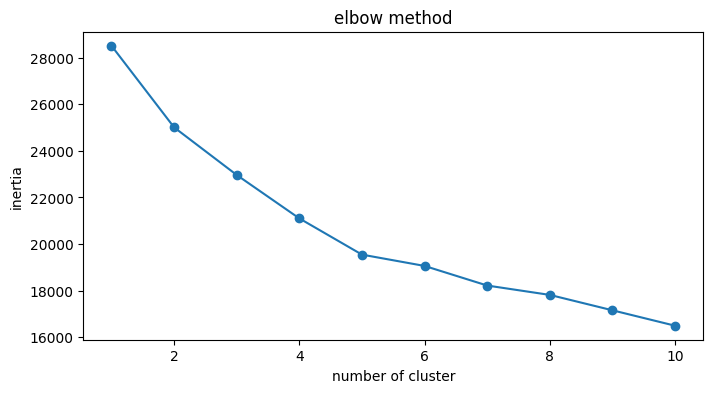

In [21]:
inertia=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit(scaled_featured)
    inertia.append(kmeans.inertia_)
plt.figure(figsize=(8,4))
plt.plot(k_values,inertia,marker='o')
plt.title('elbow method')
plt.xlabel('number of cluster')
plt.ylabel('inertia')
plt.show()

In [22]:
optimal_clusters=5
kmeans=KMeans(n_clusters=optimal_clusters,random_state=42)
data['cluster']=kmeans.fit_predict(scaled_featured)
data.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,cluster
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,2
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,2
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,4
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,4


In [23]:
score = silhouette_score(scaled_featured, data['cluster'])
print("Silhouette Score:", score)

Silhouette Score: 0.15974998009252153


In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_featured)
    score = silhouette_score(scaled_featured, labels)
    print("K =", k, "| Silhouette Score =", round(score, 4))

K = 2 | Silhouette Score = 0.123
K = 3 | Silhouette Score = 0.1202
K = 4 | Silhouette Score = 0.145
K = 5 | Silhouette Score = 0.1595
K = 6 | Silhouette Score = 0.1212
K = 7 | Silhouette Score = 0.1336
K = 8 | Silhouette Score = 0.1386
K = 9 | Silhouette Score = 0.1241
K = 10 | Silhouette Score = 0.1373


In [25]:
for k in range(11, 16):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_featured)
    score = silhouette_score(scaled_featured, labels)
    print("K =", k, "| Silhouette Score =", round(score, 4))

K = 11 | Silhouette Score = 0.1386
K = 12 | Silhouette Score = 0.1355
K = 13 | Silhouette Score = 0.1418
K = 14 | Silhouette Score = 0.148
K = 15 | Silhouette Score = 0.1347


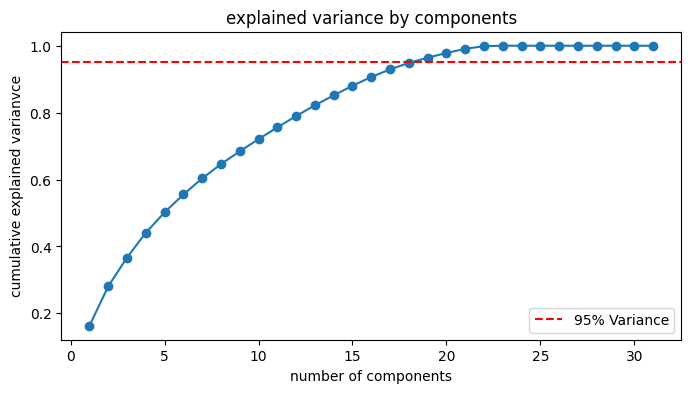

In [26]:
pca=PCA()
pca_features=pca.fit_transform(scaled_featured)
explained_variance=np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8,4))
plt.plot(range(1,len(explained_variance)+1),explained_variance,marker='o')
plt.axhline(y=0.95,color='r',linestyle='--',label='95% Variance')
plt.title('explained variance by components')
plt.xlabel('number of components')
plt.ylabel('cumulative explained varianvce')
plt.legend()
plt.show()

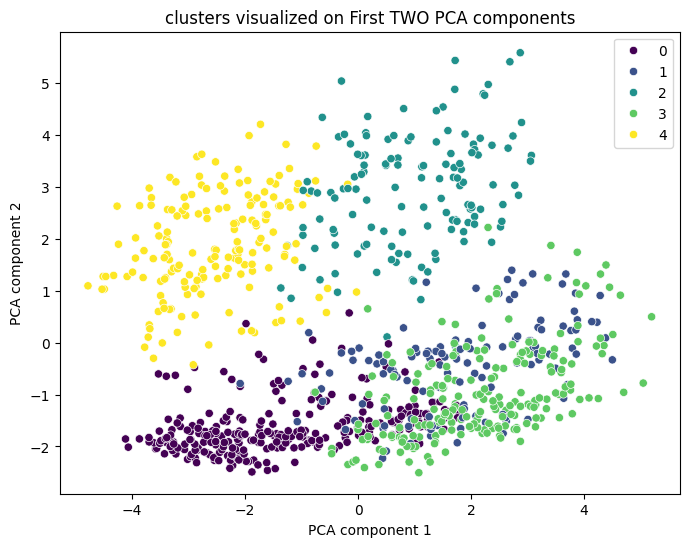

In [27]:
pca_2d=pca_features[:,:2]
plt.figure(figsize=(8,6))
sns.scatterplot(x=pca_2d[:,0],y=pca_2d[:,1],hue=data['cluster'],palette='viridis')
plt.title('clusters visualized on First TWO PCA components')
plt.xlabel('PCA component 1')
plt.ylabel('PCA component 2')
plt.legend()
plt.show()

In [28]:
data.columns

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num',
       'cluster'],
      dtype='str')

In [29]:
data['cluster'].value_counts().sort_index()

cluster
0    281
1    123
2    134
3    209
4    173
Name: count, dtype: int64

In [30]:
data.groupby('cluster')[['age','trestbps','chol','thalch','oldpeak']].mean()

,age,trestbps,chol,thalch,oldpeak
cluster,,,,,
0,47.494662,132.153967,245.875437,139.747656,0.518430
1,55.317073,130.237925,0.000000,121.687363,0.664819
2,57.447761,134.470149,249.873134,136.402985,1.732836
3,59.320574,133.934365,184.765131,126.054424,1.241786
4,51.930636,129.456647,242.832370,160.011561,0.516185


In [31]:
data.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,cluster
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,2
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,2
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,4
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,4


In [32]:
data.groupby('cluster').mean(numeric_only=True)

,id,age,trestbps,chol,thalch,oldpeak,ca,num
cluster,,,,,,,,
0,447.729537,47.494662,132.153967,245.875437,139.747656,0.518430,0.666747,0.334520
1,659.000000,55.317073,130.237925,0.000000,121.687363,0.664819,0.713921,1.804878
2,158.082090,57.447761,134.470149,249.873134,136.402985,1.732836,1.164396,1.917910
3,807.478469,59.320574,133.934365,184.765131,126.054424,1.241786,0.669903,1.507177
4,155.173410,51.930636,129.456647,242.832370,160.011561,0.516185,0.295134,0.161850


In [33]:
import joblib

model_data = {
    "model": kmeans,
    "scaler": scaler,
    "feature_columns": data_encoded.columns.tolist()
}

joblib.dump(model_data, "heart_kmeans_model.joblib")

print("Model saved successfully!")

Model saved successfully!
